# Grey-level discretization

Texture matrices (GLCM, GLRLM, GLSZM, GLDM, NGTDM) count how often
*grey levels* occur next to each other. With continuous intensities almost every voxel would have its own
value and the matrices would be empty, so the intensities inside the ROI are first grouped into a small
number of **bins**. First-order *Entropy* and *Uniformity* also use these bins.

### Fixed bin count (used here: `binCount = 32`)

The range between the smallest and the largest ROI value is cut into $N_b = 32$ equal bins:

$$ X_{b} = \begin{cases} \left\lfloor N_b \dfrac{X - X_{min}}{X_{max} - X_{min}} \right\rfloor + 1 & X < X_{max} \\[2mm]
N_b & X = X_{max} \end{cases} $$

so every ROI gets grey levels 1 … 32, whatever its intensity range. This is the IBSI-recommended choice for
MRI, where intensities have no absolute unit. (The alternative, a **fixed bin width**, is also implemented
for completeness.)

Discretization happens **after** filtering and **separately for every image type**, using only voxels
inside the ROI. Voxels outside the ROI get the value 0 and are ignored by all feature calculations.

In [1]:
import sys
from pathlib import Path

CODE_ROOT = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline")
for folder in ["", "scripts", "pre_processing", "feature_extraction", "post_processing"]:
    if str(CODE_ROOT / folder) not in sys.path:
        sys.path.insert(0, str(CODE_ROOT / folder))

import numpy as np
import pandas as pd
from discretization import *
from normalization import *
from visualize import *
import matplotlib.pyplot as plt
from filter import filtered_images

import yaml
config_path = Path("/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/config_files/setup.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config

{'DATA_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/dataset',
 'IMAGES_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/imagesTr',
 'LABELS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/dataset/labelTr',
 'PROJECT_ROOT': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'CODEBASE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline',
 'OUTPUT_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs',
 'MASK_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/masks',
 'FEATURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/features',
 'TABLE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/tables',
 'FIGURE_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/figures',
 'REGISTRATION_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/registration',
 'BIAS_DIR': '/Users/kamleshranabhat/Desktop/radiomics/full_pipeline/outputs/bias_correction',
 'REP

In [2]:
rng = np.random.default_rng(0)
for dtype in (np.float64, np.float32, np.int16):
    values = (rng.normal(100, 30, 1000)).astype(dtype)
    ours = fixed_bin_count_edges(values, 32)
    numpy_edges = np.histogram_bin_edges(values, 32).copy(); numpy_edges[-1] += 1
    print("%-8s edges dtype %-8s identical to numpy.histogram: %s | digitize identical: %s"
          % (np.dtype(dtype).name, ours.dtype, np.array_equal(ours, numpy_edges),
             np.array_equal(digitize(values, ours), np.digitize(values, numpy_edges))))

values = np.array([54.0, 60, 99, 125, 166])
print("\nfixed bin width 25 for values 54..166 -> edges", fixed_bin_width_edges(values, 25))

float64  edges dtype float64  identical to numpy.histogram: True | digitize identical: True
float32  edges dtype float32  identical to numpy.histogram: True | digitize identical: True
int16    edges dtype float64  identical to numpy.histogram: True | digitize identical: True

fixed bin width 25 for values 54..166 -> edges [ 50.  75. 100. 125. 150. 175. 200.]


In [3]:
task = ("BreastMRI023", "L", 0)
pre = preprocess(*load_task_inputs(*task, options=config["REFERENCE_OPTIONS"]))
image_cropped, mask_cropped = crop_to_roi(pre["image_array"], pre["mask_array"])
print("cropped to the ROI bounding box:", pre["image_array"].shape, "->", image_cropped.shape)

discrete, edges = discretize_with_settings(image_cropped, mask_cropped)
values = image_cropped[mask_cropped]
print("ROI intensity range %.3f .. %.3f, bin width %.3f" % (values.min(), values.max(), edges[1] - edges[0]))
print("grey levels present:", grey_levels_present(discrete, mask_cropped).tolist())
print("outside the ROI every voxel is 0:", bool((discrete[~mask_cropped] == 0).all()))

# the closed-form formula from the introduction gives the same grey levels
formula = np.floor(32 * (values - values.min()) / (values.max() - values.min())).astype(int) + 1
formula[values == values.max()] = 32
print("closed-form formula == digitize:", np.array_equal(formula, discrete[mask_cropped]))

cropped to the ROI bounding box: (117, 136, 117) -> (95, 114, 95)
ROI intensity range 106.445 .. 352.792, bin width 7.698
grey levels present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
outside the ROI every voxel is 0: True
closed-form formula == digitize: True


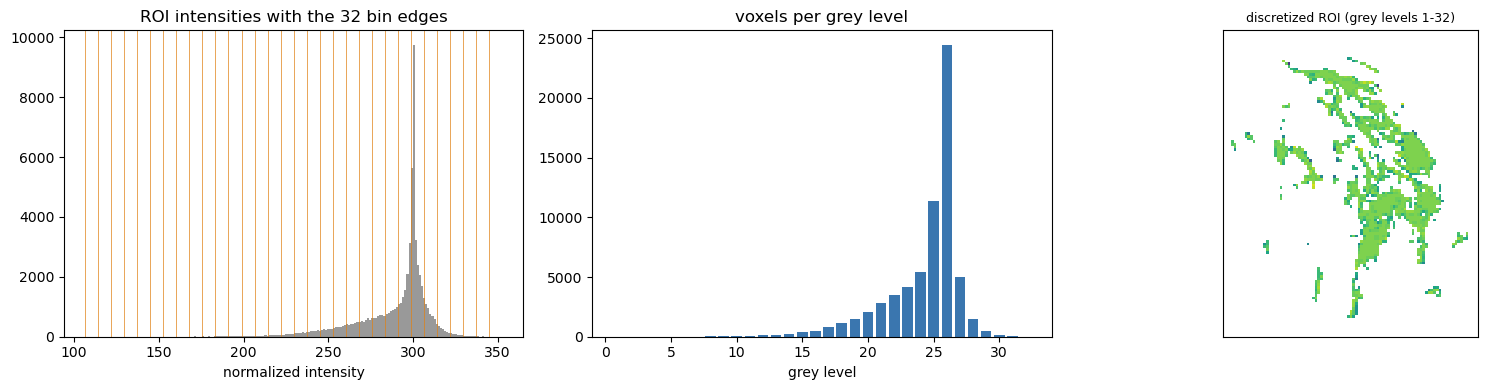

In [4]:
counts = np.bincount(discrete[mask_cropped], minlength=33)[1:]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(values, bins=200, color="0.6")
for e in edges[:-1]:
    axes[0].axvline(e, color="#e08214", lw=0.5)
axes[0].set_title("ROI intensities with the 32 bin edges"); axes[0].set_xlabel("normalized intensity")
axes[1].bar(np.arange(1, 33), counts, color="#3a76af"); axes[1].set_title("voxels per grey level")
axes[1].set_xlabel("grey level")
z = largest_slice_index(mask_cropped, 0)
show_image_with_mask(axes[2], np.where(mask_cropped, discrete, np.nan), None, pre["spacing_zyx"], 0, z,
                     title="discretized ROI (grey levels 1-32)", window=(1, 32), cmap="viridis")
fig.tight_layout()
fig.savefig(Path(config["FIGURE_DIR"]) / "discretization.png", dpi=110)
plt.show()

In [5]:
rows = []
for name, filtered in filtered_images(pre):
    a, m = crop_to_roi(filtered, pre["mask_array"])
    d, e = discretize_with_settings(a, m)
    present = grey_levels_present(d, m)
    rows.append({"image_type": name, "grey_levels_present": len(present), "highest_level": int(present.max()),
                 "bin_width": float(e[1] - e[0]), "edges_dtype": str(e.dtype)})
display(pd.DataFrame(rows))

,image_type,grey_levels_present,highest_level,bin_width,edges_dtype
0,original,32,32,7.698322,float64
1,lbp-3D-m1,32,32,0.676884,float64
2,lbp-3D-m2,32,32,0.618894,float64
3,lbp-3D-k,27,32,0.637397,float64
4,gradient,32,32,6.906997,float64
5,log-sigma-1-0-mm-3D,31,32,5.882035,float64
6,log-sigma-2-0-mm-3D,32,32,5.746575,float64
7,log-sigma-3-0-mm-3D,32,32,6.008159,float64
8,log-sigma-4-0-mm-3D,32,32,6.248236,float64
9,log-sigma-5-0-mm-3D,32,32,6.392493,float64
